# napari-lite in a notebook

`%gui qt` starts the Qt event loop inside IPython so the viewer window stays responsive while you keep working in the notebook.
`napari_lite.imshow` does this on its own when it creates the Qt application, so the magic is optional.

In [1]:
%gui qt
import time

t0 = time.perf_counter()
import napari_lite
print(f'import napari_lite: {time.perf_counter() - t0:.3f} s')

import napari_lite: 0.006 s


In [2]:
import numpy as np

# four slices of a slowly turning interference pattern
y, x = np.mgrid[0:256, 0:256] / 256
image = np.stack([np.sin(10 * x + k) * np.cos(8 * y - k) for k in range(4)])

t0 = time.perf_counter()
viewer, layer = napari_lite.imshow(image, name='pattern', colormap='magma')
print(f'first image on screen: {time.perf_counter() - t0:.3f} s')

first image on screen: 8.289 s


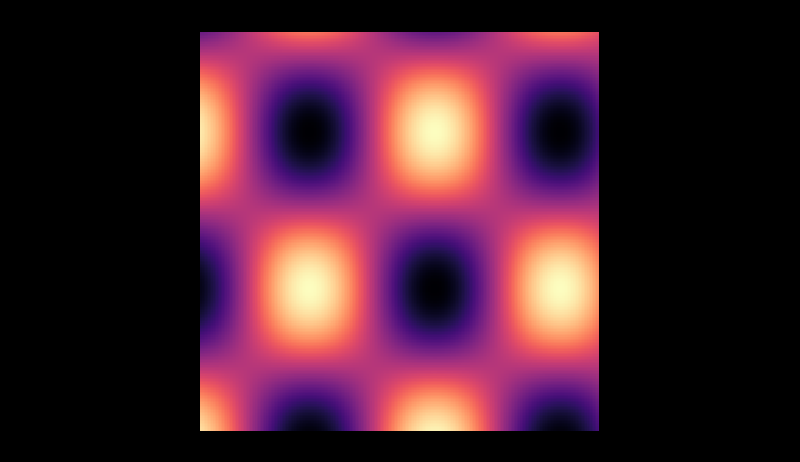

In [3]:
from napari_lite.utils import nbscreenshot

viewer.dims.current_step = (2, 0, 0)
nbscreenshot(viewer, canvas_only=True, alt_text='interference pattern, slice 2')

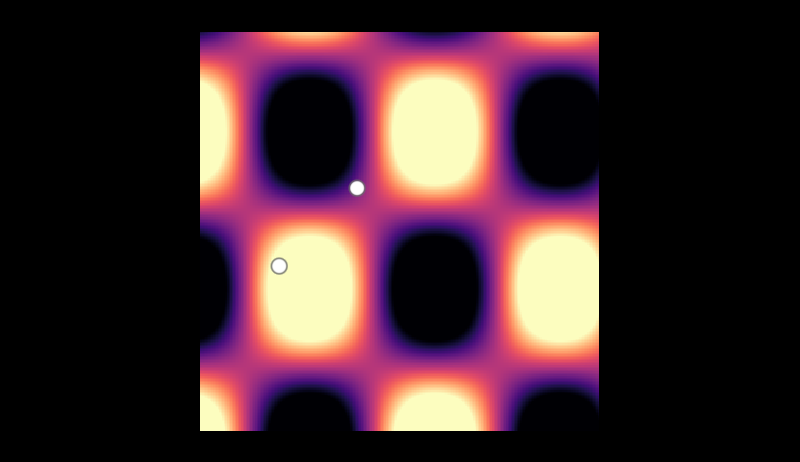

In [4]:
viewer.add_points(np.array([[2, 100, 100], [2, 150, 50]]), size=10, name='marks')
viewer.layers['pattern'].contrast_limits = (-0.5, 0.5)
nbscreenshot(viewer, canvas_only=True)

In [5]:
viewer.close()